# Electricity demand forecasting: consistent model comparison

Predict the **48 half-hours of day D** using profiles from **D−1 through D−7** and the target weekday (343 features). All models use the same observations and windows.

- Main baseline: **D−7 persistence**; additional reference: **D−1 persistence**.
- Models: **Linear**, **Ridge α=10**, **dense NN 64 → 32 → 48**.
- Five chronological windows, expanding training sets, fixed validation size.
- The former training and validation partitions form the development set. Test results are reported separately below.

These cross-validation scores are exploratory. α=10 was chosen in earlier experiments; its selection is not nested within this comparison.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import TimeSeriesSplit
from first_regression import load_development_data, run_benchmark
from demand_forecasting.evaluation import summarize_scores

RESULTS = Path("results")
# False: display saved results; True: rerun all training.
RECOMPUTE = False


## Shared windows and prevention of future-data leakage

Forecasts are updated daily using observations available through D−1. Overlapping histories are intentional. Each scaler is fitted only on the training observations of its window.

The NN uses the last 15% of its training window to select the epoch count (maximum 120, patience 12). Inner scalers exclude that portion. The network is then reinitialized and trained on the full training window for the selected number of epochs. The outer validation window never controls early stopping.


In [2]:
X, y, dates = load_development_data()
windows = []
for window, (train, val) in enumerate(TimeSeriesSplit(n_splits=5).split(X), 1):
    windows.append({
        "Window": window, "Training days": len(train),
        "Training start": str(dates[train[0]]),
        "Training end": str(dates[train[-1]]),
        "Validation days": len(val),
        "Validation start": str(dates[val[0]]),
        "Validation end": str(dates[val[-1]]),
    })
display(pd.DataFrame(windows).set_index("Window"))


,Training days,Training start,Training end,Validation days,Validation start,Validation end
Window,,,,,,
1,753,2012-01-08,2014-01-29,748,2014-01-30,2016-02-16
2,1501,2012-01-08,2016-02-16,748,2016-02-17,2018-03-05
3,2249,2012-01-08,2018-03-05,748,2018-03-06,2020-03-22
4,2997,2012-01-08,2020-03-22,748,2020-03-23,2022-04-09
5,3745,2012-01-08,2022-04-09,748,2022-04-10,2024-04-26


In [3]:
if RECOMPUTE or not (RESULTS / "cv_scores.csv").exists():
    scores, summary = run_benchmark()
    RESULTS.mkdir(exist_ok=True)
    scores.to_csv(RESULTS / "cv_scores.csv", index=False)
    summary.to_csv(RESULTS / "cv_summary.csv")
else:
    scores = pd.read_csv(RESULTS / "cv_scores.csv")
    summary = summarize_scores(scores)
display(summary.round(2))


,MAE (MW),RMSE (MW),MAE across-window std (MW),Gain MAE (%),Gain RMSE (%)
Model,,,,,
Ridge (alpha=10),969.35,1480.35,27.33,72.24,70.81
Linear,1153.25,1689.66,118.39,66.98,66.69
NN,1217.35,1722.41,115.71,65.14,66.04
Persistence D-1,2899.39,4295.47,229.28,16.98,15.31
Persistence D-7,3492.24,5072.00,188.21,0.00,0.00


## Gains and performance by window

**Gain (%) = 100 × (1 − model error / D−7 error)** on the same days. Negative gains indicate worse performance.

The summary uses MAE weighted by the number of days and the square root of weighted MSE for RMSE. The standard deviation of window MAEs describes variation across periods; it is not a confidence interval.


In [4]:
display(scores.pivot(index="Window", columns="Model", values="MAE (MW)").round(2))
display(scores.pivot(index="Window", columns="Model", values="Gain MAE (%)").round(2))
display(scores.loc[scores["Model"].eq("NN"), ["Window", "NN epochs"]].set_index("Window"))


Model,Linear,NN,Persistence D-1,Persistence D-7,Ridge (alpha=10)
Window,,,,,
1,1322.44,1305.18,3110.32,3135.46,968.51
2,1052.42,1384.08,3057.62,3515.29,932.37
3,1043.47,1059.10,3078.70,3626.70,946.45
4,1078.08,1139.66,2698.53,3667.20,1000.36
5,1269.82,1198.75,2551.78,3516.57,999.03


Model,Linear,NN,Persistence D-1,Persistence D-7,Ridge (alpha=10)
Window,,,,,
1,57.82,58.37,0.80,0.0,69.11
2,70.06,60.63,13.02,0.0,73.48
3,71.23,70.80,15.11,0.0,73.90
4,70.60,68.92,26.41,0.0,72.72
5,63.89,65.91,27.44,0.0,71.59


,NN epochs
Window,
1,117.0
2,114.0
3,97.0
4,92.0
5,80.0


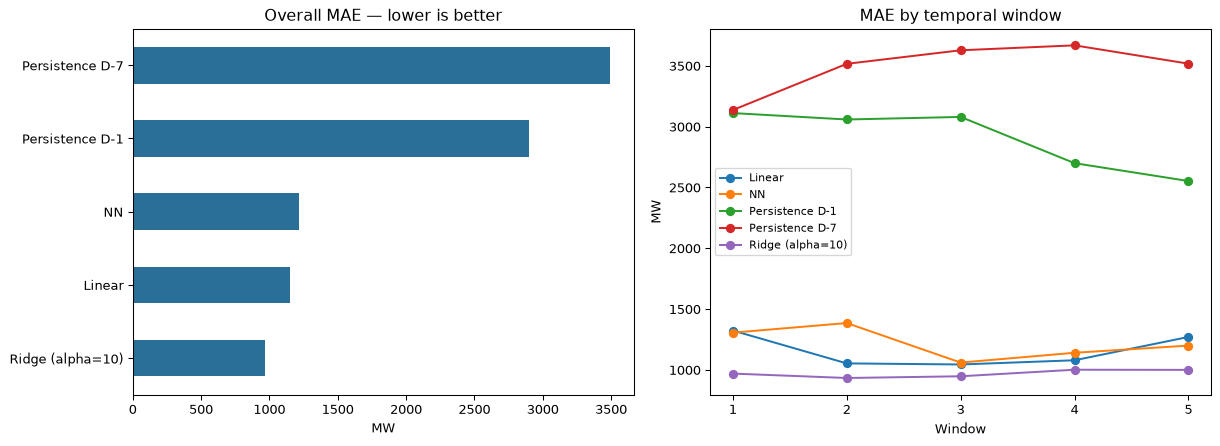

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
summary["MAE (MW)"].sort_values().plot.barh(ax=axes[0], color="#2a6f97")
axes[0].set_title("Overall MAE — lower is better")
axes[0].set_xlabel("MW")
axes[0].set_ylabel("")
scores.pivot(index="Window", columns="Model", values="MAE (MW)").plot(ax=axes[1], marker="o")
axes[1].set_title("MAE by temporal window")
axes[1].set_ylabel("MW")
axes[1].set_xticks(range(1, 6))
axes[1].legend(fontsize=8)
fig.tight_layout()
RESULTS.mkdir(exist_ok=True)
fig.savefig(RESULTS / "cv_comparison.png", dpi=160, bbox_inches="tight")
plt.show()


In [6]:
winner = summary.index[0]
print(f"Best model : {winner}.")
print(f"MAE : {summary.loc[winner, 'MAE (MW)']:.2f} MW ; "
      f"gain against D−7 : {summary.loc[winner, 'Gain MAE (%)']:.2f} %.")
reference = summary.loc["Persistence D-1", "MAE (MW)"]
print(f"MAE gain against D−1 : {100 * (1 - summary.loc[winner, 'MAE (MW)'] / reference):.2f} %.")


Best model : Ridge (alpha=10).
MAE : 969.35 MW ; gain against D−7 : 72.24 %.
MAE gain against D−1 : 66.57 %.


## Interpretation and limitations

Ridge is the best candidate in this run. The NN substantially reduces persistence errors but does not improve on the linear models overall. A single random seed cannot quantify its variability.

These results replace comparisons that mixed feature sets and partitions, so they are not directly comparable with the earlier tables. Exploratory results have already informed model choices. Because the test set was consulted previously, a future untouched period would be preferable for independent confirmation.


## Test-set reevaluation

All five models are refitted on the **4,493 development days**, then evaluated on the same **795 test days, April 27, 2024 through June 30, 2026**. Settings remain fixed from the earlier comparison. The NN selects epochs using development data only (99 epochs in this run), then refits on all development days.

Forecasts use observations available through D−1, updated daily; model parameters stay fixed throughout the test period. Test targets are not used to fit weights or select epochs.

To explicitly rerun this evaluation: `python first_regression.py --test`.


In [7]:
test_scores = pd.read_csv(RESULTS / "test_scores.csv", index_col="Model")
columns = ["MAE (MW)", "RMSE (MW)", "Gain MAE vs D-7 (%)", "Gain MAE vs D-1 (%)"]
display(test_scores[columns].round(2))


,MAE (MW),RMSE (MW),Gain MAE vs D-7 (%),Gain MAE vs D-1 (%)
Model,,,,
Ridge (alpha=10),946.32,1392.21,70.95,61.94
Linear,953.72,1379.03,70.72,61.64
NN,1164.68,1597.63,64.24,53.16
Persistence D-1,2486.28,3626.02,23.67,0.00
Persistence D-7,3257.19,4790.46,0.00,-31.01


Ridge has the lowest MAE (946.32 MW), a **61.94% reduction against D−1** and **70.95% against D−7**. Linear is close in MAE (953.72 MW) and has the lowest RMSE (1,379.03 MW versus 1,392.21 MW). The NN trails both linear models.

The MAE difference between Ridge and Linear is 7.39 MW, approximately 0.78%; this ranking alone does not establish statistical superiority. The test set was consulted during earlier exploration, so reevaluation does not restore an independent final assessment.
